In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/vhap")
IMG = ROOT / "data" / "ueyes_web" / "images"
SAL = ROOT / "data" / "ueyes_web" / "saliency_maps"
FIX = ROOT / "data" / "ueyes_web" / "fixations"
WTS = ROOT / "models" / "transalnet_pretrained"

for p in (IMG, SAL, FIX, WTS / "TranSalNet_Res.pth", WTS / "resnet50-0676ba61.pth"):
    print(("OK " if p.exists() else "MISSING "), p)
print("images", len(list(IMG.glob("*"))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK  /content/drive/MyDrive/vhap/data/ueyes_web/images
OK  /content/drive/MyDrive/vhap/data/ueyes_web/saliency_maps
OK  /content/drive/MyDrive/vhap/data/ueyes_web/fixations
OK  /content/drive/MyDrive/vhap/models/transalnet_pretrained/TranSalNet_Res.pth
OK  /content/drive/MyDrive/vhap/models/transalnet_pretrained/resnet50-0676ba61.pth
images 495


In [3]:
%cd /content
!git clone https://github.com/LJOVO/TranSalNet.git
!mkdir -p /content/TranSalNet/pretrained_models
!cp /content/drive/MyDrive/vhap/models/transalnet_pretrained/TranSalNet_Res.pth /content/TranSalNet/pretrained_models/
!cp /content/drive/MyDrive/vhap/models/transalnet_pretrained/resnet50-0676ba61.pth /content/TranSalNet/pretrained_models/
!ls -lh /content/TranSalNet/pretrained_models

/content
Cloning into 'TranSalNet'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 58 (delta 6), reused 3 (delta 3), pack-reused 43 (from 1)
Receiving objects: 100% (58/58), 3.14 MiB | 22.51 MiB/s, done.
Resolving deltas: 100% (9/9), done.
total 375M
-rw------- 1 root root  98M Oct 15 17:31 resnet50-0676ba61.pth
-rw------- 1 root root 277M Oct 15 17:31 TranSalNet_Res.pth


In [4]:
from pathlib import Path
p = Path("/content/TranSalNet/utils/resnet.py")
old = "state_dict = torch.load(r'pretrained_models/resnet50-0676ba61.pth')"
new = "state_dict = torch.load(r'pretrained_models/resnet50-0676ba61.pth', weights_only=False)"
text = p.read_text()
if old in text:
    p.write_text(text.replace(old, new, 1))
    print("patched")
else:
    print("already patched or the line differs")

patched


In [5]:
%cd /content/TranSalNet
import torch
from TranSalNet_Res import TranSalNet

device = "cuda" if torch.cuda.is_available() else "cpu"
model = TranSalNet()
state = torch.load("pretrained_models/TranSalNet_Res.pth", map_location=device, weights_only=False)
model.load_state_dict(state)
model = model.to(device).eval()
print("Model 1 loaded on", device)

/content/TranSalNet
Model 1 loaded on cuda


In [6]:
import json, random
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/vhap")
IMG = ROOT / "data" / "ueyes_web" / "images"
split_path = ROOT / "data" / "splits.json"

if split_path.exists():
    splits = json.loads(split_path.read_text())
    print("Loaded the existing split. Do not delete or rebuild it.")
else:
    pages = sorted(p.stem for p in IMG.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"})
    random.seed(42)
    random.shuffle(pages)
    n = len(pages)
    n_train, n_val = int(0.70 * n), int(0.15 * n)
    splits = {
        "train": pages[:n_train],
        "val": pages[n_train:n_train + n_val],
        "test": pages[n_train + n_val:],
    }
    split_path.write_text(json.dumps(splits, indent=2))
    print("Wrote", split_path)

print({k: len(v) for k, v in splits.items()})

Wrote /content/drive/MyDrive/vhap/data/splits.json
{'train': 346, 'val': 74, 'test': 75}


In [8]:
import cv2
import numpy as np
import torch
from utils.data_process import preprocess_img

def find_by_stem(folder, stem):
    folder = Path(folder)
    for ext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        hit = folder / f"{stem}{ext}"
        if hit.exists():
            return hit
    hits = list(folder.glob(stem + ".*"))
    return hits[0] if hits else None

def postprocess_float(pred, orig_h, orig_w):
    pred = pred.astype(np.float32)
    pred_h, pred_w = pred.shape[:2]
    if (orig_h / pred_h) > (orig_w / pred_w):
        new_cols = (pred_w * orig_h) // pred_h
        pred = cv2.resize(pred, (new_cols, orig_h), interpolation=cv2.INTER_LINEAR)
        start = (pred.shape[1] - orig_w) // 2
        pred = pred[:, start:start + orig_w]
    else:
        new_rows = (pred_h * orig_w) // pred_w
        pred = cv2.resize(pred, (orig_w, new_rows), interpolation=cv2.INTER_LINEAR)
        start = (pred.shape[0] - orig_h) // 2
        pred = pred[start:start + orig_h, :]
    if pred.shape[:2] != (orig_h, orig_w):
        pred = cv2.resize(pred, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    return np.clip(pred, 0, 1)

def predict_map(model, image_path, device):
    padded = preprocess_img(str(image_path))
    x = np.transpose(padded.astype(np.float32) / 255.0, (2, 0, 1))[None]
    with torch.no_grad():
        y = model(torch.from_numpy(x).to(device))[0, 0].cpu().numpy()
    orig = cv2.imread(str(image_path))
    h, w = orig.shape[:2]
    return postprocess_float(y, h, w)

In [9]:
import matplotlib.pyplot as plt

preview_dir = ROOT / "results" / "model1_previews"
preview_dir.mkdir(parents=True, exist_ok=True)

for stem in splits["train"][:8]:
    image_path = find_by_stem(IMG, stem)
    gt_path = find_by_stem(SAL, stem)
    pred = predict_map(model, image_path, device)
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    gt = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)
    gt = cv2.resize(gt, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_AREA)
    gt = gt.astype(np.float32) / (gt.max() + 1e-8)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].imshow(image); axes[0].set_title("Screenshot")
    axes[1].imshow(gt, cmap="jet"); axes[1].set_title("Human heatmap, 3s")
    axes[2].imshow(pred, cmap="jet"); axes[2].set_title("Model 1, SALICON")
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(preview_dir / f"{stem}.png", dpi=120)
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [10]:
out_local = Path("/content/model1_test_maps")
out_local.mkdir(exist_ok=True)

for i, stem in enumerate(splits["test"], start=1):
    image_path = find_by_stem(IMG, stem)
    pred = predict_map(model, image_path, device)
    np.save(out_local / f"{stem}.npy", pred.astype(np.float32))
    if i % 10 == 0 or i == len(splits["test"]):
        print(f"{i}/{len(splits['test'])}")

import shutil
dest = ROOT / "results" / "model1_test_maps"
if dest.exists():
    shutil.rmtree(dest)
shutil.copytree(out_local, dest)
print("Saved", len(list(dest.glob('*.npy'))), "maps to", dest)

10/75
20/75
30/75
40/75
50/75
60/75
70/75
75/75
Saved 75 maps to /content/drive/MyDrive/vhap/results/model1_test_maps


In [11]:
import csv

def map_cc(pred, gt):
    p = pred.astype(np.float64).ravel()
    g = gt.astype(np.float64).ravel()
    p = (p - p.mean()) / (p.std() + 1e-8)
    g = (g - g.mean()) / (g.std() + 1e-8)
    return float((p * g).mean())

def map_kl(pred, gt):
    p = pred.astype(np.float64)
    g = gt.astype(np.float64)
    p = p / (p.sum() + 1e-8)
    g = g / (g.sum() + 1e-8)
    return float((g * np.log((g + 1e-8) / (p + 1e-8))).sum())

def map_nss(pred, fix):
    f = (fix.astype(np.float64) > 0)
    if f.sum() < 1:
        return float("nan")
    p = pred.astype(np.float64)
    p = (p - p.mean()) / (p.std() + 1e-8)
    return float(p[f].mean())

rows = []
for stem in splits["test"]:
    pred = np.load(dest / f"{stem}.npy")
    gt_path = find_by_stem(SAL, stem)
    fix_path = find_by_stem(FIX, stem)
    gt = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
    fix = cv2.imread(str(fix_path), cv2.IMREAD_GRAYSCALE)
    h, w = pred.shape[:2]
    gt = cv2.resize(gt, (w, h), interpolation=cv2.INTER_AREA)
    fix = cv2.resize(fix, (w, h), interpolation=cv2.INTER_NEAREST)
    rows.append({"id": stem, "cc": map_cc(pred, gt), "kl": map_kl(pred, gt), "nss": map_nss(pred, fix)})

csv_path = ROOT / "results" / "model1_test_metrics.csv"
with csv_path.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["id", "cc", "kl", "nss"])
    writer.writeheader()
    writer.writerows(rows)

cc = np.mean([r["cc"] for r in rows])
kl = np.mean([r["kl"] for r in rows])
nss = np.nanmean([r["nss"] for r in rows])
summary = f"Model 1 test  n={len(rows)}  CC={cc:.4f}  KL={kl:.4f}  NSS={nss:.4f}\n"
(ROOT / "results" / "model1_test_summary.txt").write_text(summary)
print(summary)

Model 1 test  n=75  CC=0.4055  KL=1.2137  NSS=0.9971



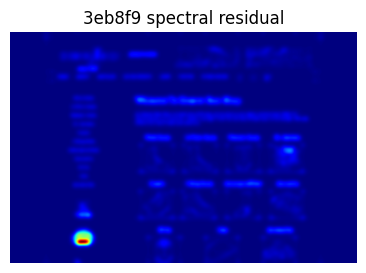

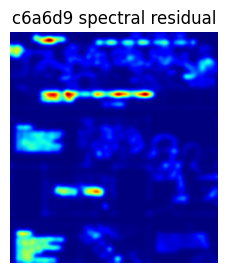

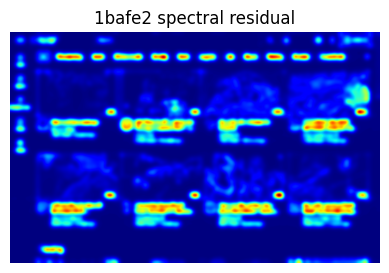

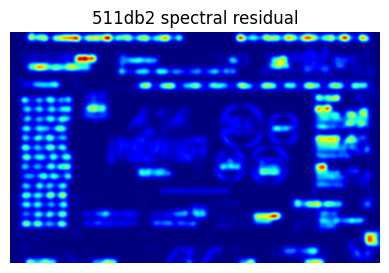

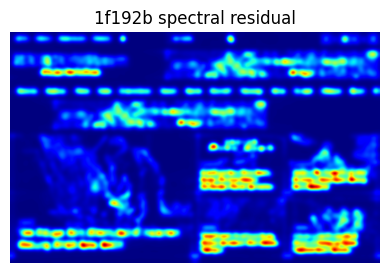

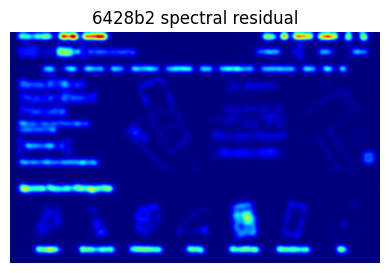

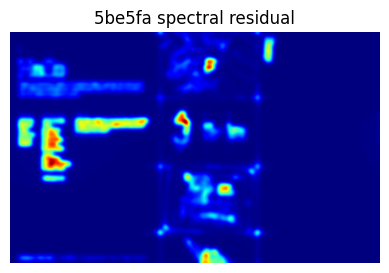

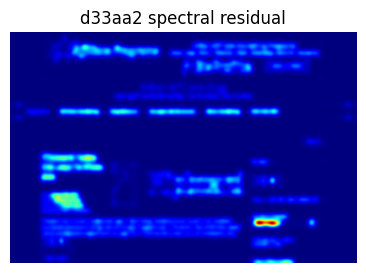

In [12]:
def spectral_residual(image_path):
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE).astype(np.float32)
    freq = np.fft.fft2(gray)
    log_amp = np.log(np.abs(freq) + 1e-8)
    phase = np.angle(freq)
    residual = log_amp - cv2.blur(log_amp, (3, 3))
    sal = np.abs(np.fft.ifft2(np.exp(residual + 1j * phase))) ** 2
    sal = cv2.GaussianBlur(sal.astype(np.float32), (0, 0), 8)
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)
    return sal

sr_dir = ROOT / "results" / "spectral_residual_previews"
sr_dir.mkdir(parents=True, exist_ok=True)
for stem in splits["train"][:8]:
    image_path = find_by_stem(IMG, stem)
    sal = spectral_residual(image_path)
    plt.figure(figsize=(6, 3))
    plt.imshow(sal, cmap="jet")
    plt.axis("off")
    plt.title(stem + " spectral residual")
    plt.savefig(sr_dir / f"{stem}.png", dpi=120)
    plt.show()